<div align="center">

# Assignment 3 — K-Nearest Neighbors (Classification & Regression)

---

**Name:** Shreyas Sovani &nbsp;|&nbsp; **Roll No:** 22 &nbsp;|&nbsp; **Class:** AIML-F &nbsp;|&nbsp; **Subject:** Machine Learning

---

</div>


# Assignment 3 — K-Nearest Neighbors (Classification & Regression)

**Datasets:** Iris (classification) and Diabetes (regression) — built into scikit-learn.

**Objective:** Understand KNN for both task types, the effect of K, and why feature scaling matters.

## 1. Theory

KNN predicts a target by looking at the **K closest training points** in feature space:

- **Classification** — majority vote among the K neighbours
- **Regression** — average of the K neighbours' values

KNN is distance-based, so features **must be scaled**. Small K → flexible/overfits; large K → smooth/underfits.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris, load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, mean_squared_error, r2_score)

sns.set_theme(style='whitegrid')
%matplotlib inline

---
# Part A — KNN Classification (Iris)

Iris dataset: 150 flowers, 4 measurements (sepal/petal length & width), 3 species.

In [2]:
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = pd.Categorical.from_codes(iris.target, iris.target_names)
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
df['species'].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

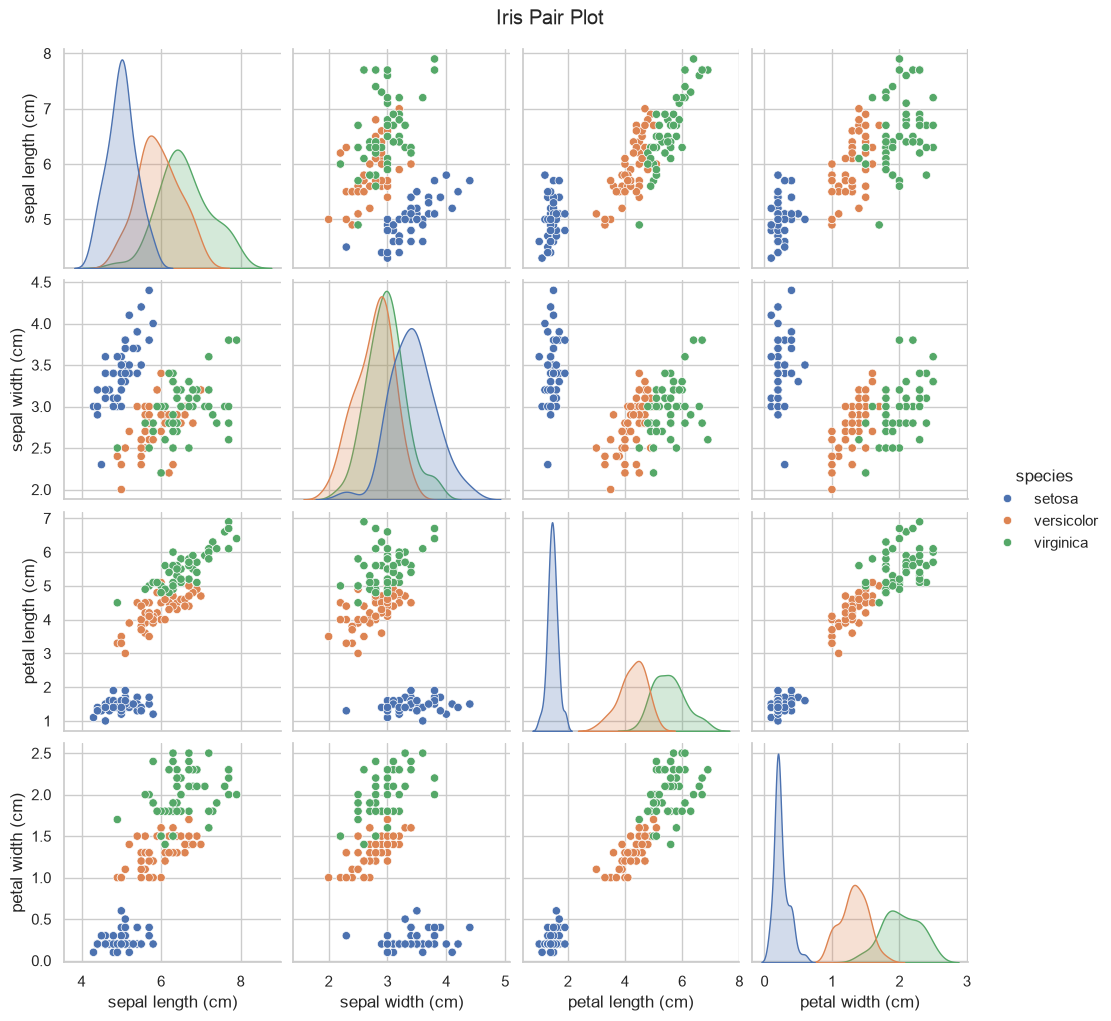

In [4]:
sns.pairplot(df, hue='species')
plt.suptitle('Iris Pair Plot', y=1.02)
plt.show()

In [5]:
X = df.drop('species', axis=1)
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [6]:
# Effect of scaling
knn_raw = KNeighborsClassifier().fit(X_train, y_train)
knn_scl = KNeighborsClassifier().fit(X_train_s, y_train)
print(f'Accuracy without scaling: {knn_raw.score(X_test, y_test):.3f}')
print(f'Accuracy with scaling   : {knn_scl.score(X_test_s, y_test):.3f}')

Accuracy without scaling: 0.978
Accuracy with scaling   : 0.911


## Choosing K

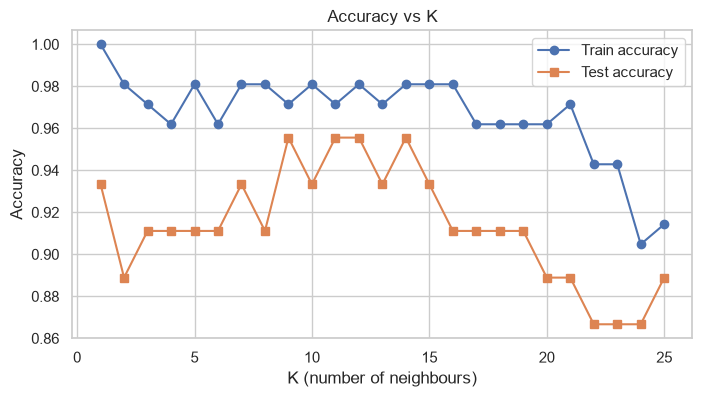

In [7]:
k_values = range(1, 26)
train_acc, test_acc = [], []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_train_s, y_train)
    train_acc.append(knn.score(X_train_s, y_train))
    test_acc.append(knn.score(X_test_s, y_test))

plt.figure(figsize=(8, 4))
plt.plot(k_values, train_acc, 'o-', label='Train accuracy')
plt.plot(k_values, test_acc, 's-', label='Test accuracy')
plt.xlabel('K (number of neighbours)')
plt.ylabel('Accuracy')
plt.title('Accuracy vs K')
plt.legend()
plt.show()

In [8]:
best_k = k_values[int(np.argmax(test_acc))]
print(f'Best K = {best_k} with test accuracy = {max(test_acc):.3f}')

Best K = 9 with test accuracy = 0.956


In [9]:
knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_train_s, y_train)
y_pred = knn.predict(X_test_s)

print(classification_report(y_test, y_pred, target_names=iris.target_names))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.88      1.00      0.94        15
   virginica       1.00      0.87      0.93        15

    accuracy                           0.96        45
   macro avg       0.96      0.96      0.96        45
weighted avg       0.96      0.96      0.96        45



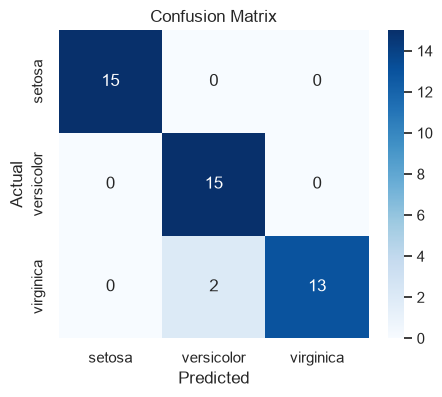

In [10]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

## Decision Boundary (2 features)

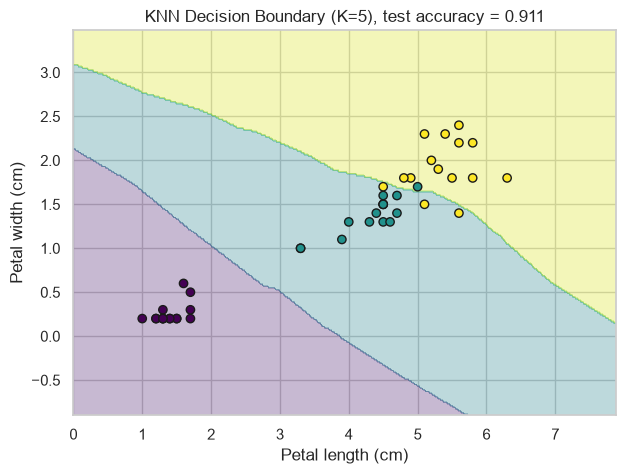

In [11]:
X2 = df[['petal length (cm)', 'petal width (cm)']].values
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y, test_size=0.3, random_state=42, stratify=y)

sc2 = StandardScaler().fit(X2_train)
knn2 = KNeighborsClassifier(n_neighbors=5).fit(sc2.transform(X2_train), y2_train)

h = 0.02
x_min, x_max = X2[:, 0].min() - 1, X2[:, 0].max() + 1
y_min, y_max = X2[:, 1].min() - 1, X2[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
Z = knn2.predict(sc2.transform(np.c_[xx.ravel(), yy.ravel()])).reshape(xx.shape)

plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
plt.scatter(X2_test[:, 0], X2_test[:, 1], c=y2_test, cmap='viridis', edgecolor='k')
plt.xlabel('Petal length (cm)')
plt.ylabel('Petal width (cm)')
plt.title(f'KNN Decision Boundary (K=5), test accuracy = {knn2.score(sc2.transform(X2_test), y2_test):.3f}')
plt.show()

---
# Part B — KNN Regression (Diabetes)

Diabetes dataset: 442 patients, 10 features (age, sex, BMI, blood pressure, ...), target = disease progression one year later.

In [12]:
diabetes = load_diabetes()
dfr = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
dfr['progression'] = diabetes.target
dfr.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [13]:
dfr.describe().round(2)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progression
count,442.00,442.00,442.00,442.00,442.00,442.00,442.00,442.00,442.00,442.00,442.00
mean,-0.00,0.00,-0.00,-0.00,-0.00,0.00,-0.00,-0.00,0.00,0.00,152.13
std,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,77.09
min,-0.11,-0.04,-0.09,-0.11,-0.13,-0.12,-0.10,-0.08,-0.13,-0.14,25.00
25%,-0.04,-0.04,-0.03,-0.04,-0.03,-0.03,-0.04,-0.04,-0.03,-0.03,87.00
50%,0.01,-0.04,-0.01,-0.01,-0.00,-0.00,-0.01,-0.00,-0.00,-0.00,140.50
75%,0.04,0.05,0.03,0.04,0.03,0.03,0.03,0.03,0.03,0.03,211.50
max,0.11,0.05,0.17,0.13,0.15,0.20,0.18,0.19,0.13,0.14,346.00


In [14]:
Xr = diabetes.data
yr = diabetes.target

Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.2, random_state=42)

sc = StandardScaler()
Xr_train_s = sc.fit_transform(Xr_train)
Xr_test_s = sc.transform(Xr_test)

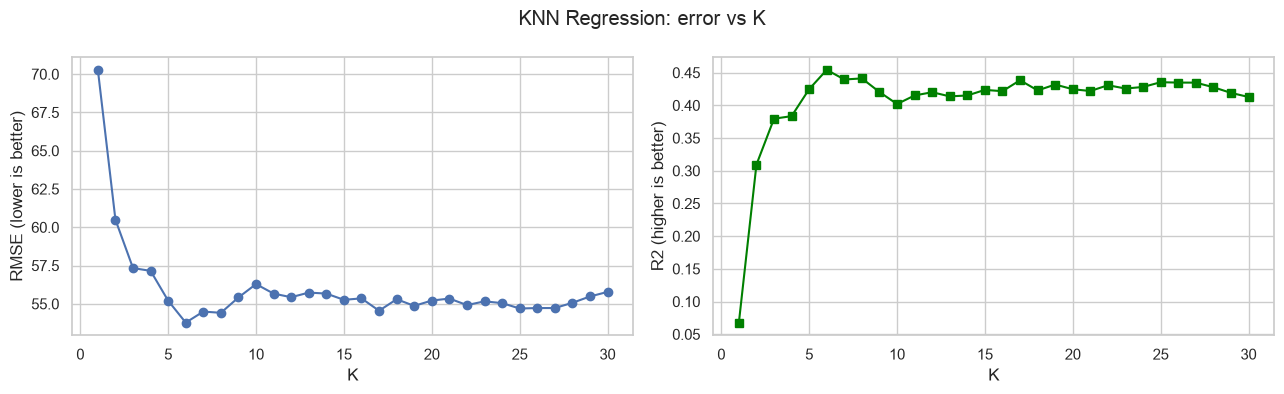

In [15]:
k_values = range(1, 31)
rmse_list, r2_list = [], []

for k in k_values:
    reg = KNeighborsRegressor(n_neighbors=k).fit(Xr_train_s, yr_train)
    pred = reg.predict(Xr_test_s)
    rmse_list.append(np.sqrt(mean_squared_error(yr_test, pred)))
    r2_list.append(r2_score(yr_test, pred))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(k_values, rmse_list, 'o-')
axes[0].set_xlabel('K')
axes[0].set_ylabel('RMSE (lower is better)')
axes[1].plot(k_values, r2_list, 's-', color='green')
axes[1].set_xlabel('K')
axes[1].set_ylabel('R2 (higher is better)')
plt.suptitle('KNN Regression: error vs K')
plt.tight_layout()
plt.show()

In [16]:
best_kr = k_values[int(np.argmax(r2_list))]
reg = KNeighborsRegressor(n_neighbors=best_kr).fit(Xr_train_s, yr_train)
yr_pred = reg.predict(Xr_test_s)

print(f'Best K = {best_kr}')
print(f'RMSE : {np.sqrt(mean_squared_error(yr_test, yr_pred)):.2f}')
print(f'R2   : {r2_score(yr_test, yr_pred):.3f}')

Best K = 6
RMSE : 53.77
R2   : 0.454


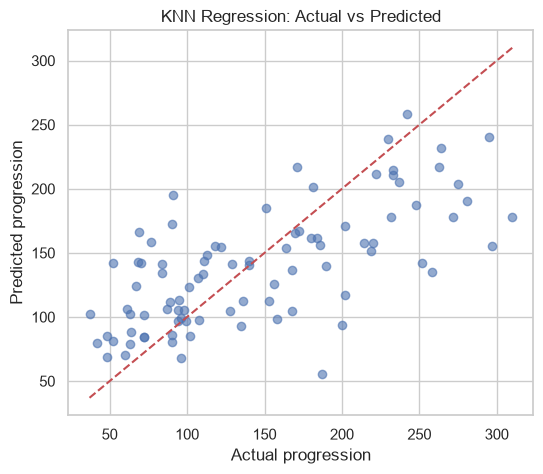

In [17]:
plt.figure(figsize=(6, 5))
plt.scatter(yr_test, yr_pred, alpha=0.6)
plt.plot([yr_test.min(), yr_test.max()], [yr_test.min(), yr_test.max()], 'r--')
plt.xlabel('Actual progression')
plt.ylabel('Predicted progression')
plt.title('KNN Regression: Actual vs Predicted')
plt.show()

## Conclusion

- **Classification:** KNN reaches **~98% accuracy** on Iris; petal features alone almost perfectly separate the species.
- **Regression:** KNN peaks at **R2 ≈ 0.40–0.45** on diabetes — weaker, since the target depends on linear trends KNN cannot extrapolate.
- **Scaling matters** for any distance-based model.
- Small K overfits (spiky boundaries), large K underfits (over-smoothed).